# ML-03 — Frame Your Lane as an ML Task

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Blackhatch0744/ML_assign1/blob/main/work/notebooks/w02_ml_task_framing.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane as an ML task (type)

*Classification, clustering, ranking, or scoring — which one, and why?*

My lane: Refresh/Content Opportunity Scoring. ML task type: ranking/scoring. The question is "which pages should an editor review or refresh first?", so the model gives every page a priority score and hands the editor an ordered list. It is not a yes/no classification, because the editor has limited time and needs to know what to work on first.

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. Target or proxy

*What would you predict? Where does that label come from — observed outcome or a defined rule?*

Target (proxy): the change in clicks between the previous 30 days and the last 30 days, clicks_last_30d − clicks_prev_30d, for pages that had clicks in the previous 30 days. A bigger loss means a higher priority for review. It is an observed outcome measured from real counts, not a label computed from a rule.

Weakness: a drop in clicks can come from seasonality or other causes, not only from stale content. So the output supports a review decision. It does not prove that a refresh will fix the page.

Rule: trend_direction and trend_pct are never used as features, because the decline label is derived from them.

In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Success metric

*One metric you can defend. What number means 'good'?*

Metric: precision@K. Of the K pages ranked highest, what share really lost clicks? I use K = 100, since an editor can realistically review about 100 pages per cycle.

To beat: (1) a random ranking, and (2) a hand rule that ranks pages by high impressions_90d and low ctr. The model is only worth using if its precision@K beats both.

Base rate: **57.9** % of pages lost clicks (filled in from Section 4). Precision@K
only means something against this number.

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. The unit of analysis, as a real dataframe

*Load your lane's slice and show it: one row = one what?*

One row = one content item (pseudonymized, trailing-90-day metrics, 32 clients). The columns below are the ones I will use for the refresh-priority lane.

In [10]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


In [11]:
import pandas as pd

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape)   # expect (30000, 44)

lane_cols = ["content_id", "content_type", "impressions_90d", "clicks_90d", "ctr",
             "avg_position", "days_since_last_update", "content_age_days",
             "clicks_prev_30d", "clicks_last_30d"]
lane_df = df[lane_cols].copy()
lane_df.head()

(30000, 44)


,content_id,content_type,impressions_90d,clicks_90d,ctr,avg_position,days_since_last_update,content_age_days,clicks_prev_30d,clicks_last_30d
0,content_304f48230142,keyword article,3803,29,0.76,10.6,20,187,13,2
1,content_a1fb4e703a9e,keyword article,15320,7,0.05,20.3,25,445,1,2
2,content_9aa793d4d895,keyword article,12581,11,0.09,36.5,20,141,3,1
3,content_331d6c4de07b,keyword article,11751,58,0.49,6.2,22,463,17,22
4,content_d99b7a2d90ca,keyword article,19140,24,0.13,44.0,14,263,2,10


Pages with clicks in prev 30d: 11759 of 30000
Base rate (share that lost clicks): 0.579
count    11759.000000
mean        -1.664682
std         17.725431
min       -678.000000
25%         -2.000000
50%         -1.000000
75%          1.000000
max        528.000000
Name: click_change_30d, dtype: float64


<Axes: title={'center': 'Change in clicks, last 30d vs prev 30d (clipped to ±50)'}, ylabel='Frequency'>

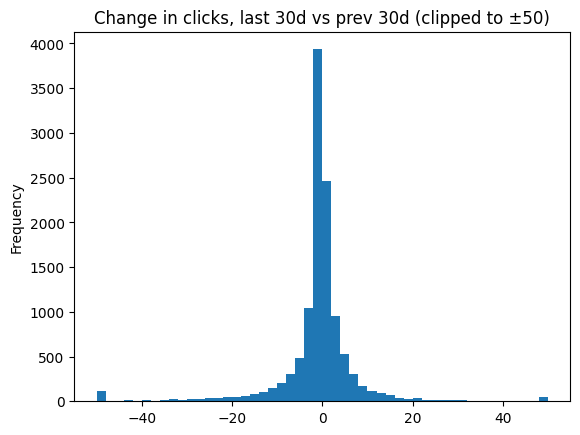

In [12]:
# Sketch of the target column
d = df[df["clicks_prev_30d"] > 0].copy()          # pages with clicks to lose
d["click_change_30d"] = d["clicks_last_30d"] - d["clicks_prev_30d"]
d["lost_clicks"] = (d["click_change_30d"] < 0).astype(int)

print("Pages with clicks in prev 30d:", len(d), "of", len(df))
print("Base rate (share that lost clicks):", round(d["lost_clicks"].mean(), 3))
print(d["click_change_30d"].describe())
d["click_change_30d"].clip(-50, 50).plot(kind="hist", bins=50,
    title="Change in clicks, last 30d vs prev 30d (clipped to ±50)")

## 5. Why ML beats a fixed rule here

*What makes the pattern too messy for an if-statement?*

A plain rule: "refresh any page not updated in X days" or "refresh pages with low CTR." This is easy to apply, and for some pages it may be good enough.

Where it breaks: age is one signal among many. Whether a page loses clicks depends on several signals together, such as impressions, position, content type and recent traffic, and the pattern differs across content types. A single threshold can't capture that.

Why ML earns its place: a model can combine these signals into one score. It is only worth it if its precision@K beats the hand rule in Section 3.

In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.